# Otimização do Random Forest – Passo 7: congelar e testar (abordagem B)

**Regra de ouro:** a configuração é gravada em `config_final_B.json` **antes** de gerar qualquer previsão do teste.
O teste (01/2025–03/2026) roda uma única vez. Depois, o período novo (04–09/2026), que nenhum modelo do projeto usou
para escolher nada, serve de confirmação.

**Duas regras, decididas antes de ver o teste:**

| Regra | Definição | Papel |
|---|---|---|
| **Oficial** | Opera todo minuto (sem trava) | Pelo protocolo: nenhuma regra passou na trava (t ≥ 2) na validação, então vale a regra padrão, que não foi escolhida olhando resultado |
| **Sensibilidade** | Opera só nos 2% de minutos com sinal mais forte (limiar congelado da validação), uma operação por minuto | A melhor regra da validação com o modelo final (−2,67 pts/op), mostrada como "melhor uso possível", sem ter passado na trava |

Custos de 0, 5 e 10 pts. Referência aleatória (mesmos minutos, direção sorteada).

In [1]:
import os, sys, json, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    PASTA = "/content/data_science_no_mercado_financeiro"
    if not os.path.exists(PASTA):
        subprocess.run(["git", "clone", "https://github.com/anabiaboorges/data_science_no_mercado_financeiro.git", PASTA], check=True)
except ImportError:
    PASTA = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

sys.path.append(PASTA)
sys.path.append(f"{PASTA}/frentes/ml")
import tt1_comum as t
import otim_rf as o

SAIDA = f"{PASTA}/resultados/ml/otimizacao"
D4 = json.load(open(f"{SAIDA}/decisao_passo4.json", encoding="utf-8"))
D5 = json.load(open(f"{SAIDA}/decisao_passo5.json", encoding="utf-8"))
D6 = json.load(open(f"{SAIDA}/decisao_passo6.json", encoding="utf-8"))
CANDLE, JANELA, FEATS, RF, CORTE = D4["candle"], D4["janela_meses"], D5["variaveis"], D6["rf"], D6["corte_classe"]
NOVO = ("2026-04-01", "2026-09-26")

# previsões de validação do modelo final (passo 6); recria se faltarem
win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
wdo = t.carregar(f"{PASTA}/dados/WDON_M1/WDO$N_M1.csv")
df_comum, _ = t.montar_base(win, wdo, CANDLE)
DF = o.rotular(o.adicionar_features(df_comum), CORTE)
arq_val = f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_rfB_{D6['modelo']}_val.csv"
if os.path.exists(arq_val):
    PREV_VAL = pd.read_csv(arq_val, index_col=0, parse_dates=True)
else:
    PREV_VAL, _ = o.walk_forward_b(DF, FEATS, *t.VALIDACAO, janela_meses=JANELA, rf=RF)

Q_SENS = 0.98
LIM_SENS = float(np.quantile(np.abs(PREV_VAL.sinal), Q_SENS))
CONFIG = dict(abordagem="B: RandomForestClassifier 3 classes, sinal = P(sobe) − P(desce)", candle=CANDLE,
              janela_meses=JANELA, retreino="trimestral", variaveis=FEATS, n_variaveis=len(FEATS), floresta=RF,
              corte_classe_pts=CORTE, custo_escolha_pts=o.CUSTO,
              regra_oficial=dict(nome="opera sempre", limiar=0.0,
                                 motivo="nenhuma regra com esperança > 0, t ≥ 2 e ≥ 3 trimestres na validação"),
              regra_sensibilidade=dict(nome="por_candle, 2% mais fortes", limiar_q=Q_SENS, limiar=LIM_SENS,
                                       motivo="melhor esperança da validação com o modelo final, sem passar na trava"),
              congelado_antes_do_teste=True)
json.dump(CONFIG, open(f"{SAIDA}/config_final_B.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print(json.dumps({k: v for k, v in CONFIG.items() if k != "variaveis"}, ensure_ascii=False, indent=1))

{
 "abordagem": "B: RandomForestClassifier 3 classes, sinal = P(sobe) − P(desce)",
 "candle": "1min",
 "janela_meses": 12,
 "retreino": "trimestral",
 "n_variaveis": 30,
 "floresta": {
  "n_estimators": 100,
  "max_depth": 4,
  "max_features": 0.5,
  "folha_frac": 0.02,
  "folha_min": 10
 },
 "corte_classe_pts": 5.0,
 "custo_escolha_pts": 5.0,
 "regra_oficial": {
  "nome": "opera sempre",
  "limiar": 0.0,
  "motivo": "nenhuma regra com esperança > 0, t ≥ 2 e ≥ 3 trimestres na validação"
 },
 "regra_sensibilidade": {
  "nome": "por_candle, 2% mais fortes",
  "limiar_q": 0.98,
  "limiar": 0.03624652315710347,
  "motivo": "melhor esperança da validação com o modelo final, sem passar na trava"
 },
 "congelado_antes_do_teste": true
}


## Rodada única: teste e período novo

O período novo usa a base só do WIN (o WDO termina em 01/04/2026); as variáveis do modelo não usam o WDO.

In [2]:
df_win, _ = t.montar_base(win, win, CANDLE)
DF_WIN = o.rotular(o.adicionar_features(df_win), CORTE)
PREV = {"validacao_2024": PREV_VAL}
t0 = time.time()
PREV["teste_2025_03-2026"], _ = o.walk_forward_b(DF, FEATS, *t.TESTE, janela_meses=JANELA, rf=RF, verbose=True)
PREV["novo_04-09-2026"], _ = o.walk_forward_b(DF_WIN, FEATS, *NOVO, janela_meses=JANELA, rf=RF, verbose=True)
for k in ["teste_2025_03-2026", "novo_04-09-2026"]:
    PREV[k].to_csv(f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_rfB_final_{k}.csv")
print(f"{time.time() - t0:.0f}s")

  2025-01-01: treino 141,215 (folha mín. 2824) | prevê 34,160


  2025-04-01: treino 141,227 (folha mín. 2824) | prevê 34,329


  2025-07-01: treino 140,047 (folha mín. 2800) | prevê 37,108


  2025-10-01: treino 139,992 (folha mín. 2799) | prevê 34,867


  2026-01-01: treino 140,463 (folha mín. 2809) | prevê 34,115


  2026-04-01: treino 140,436 (folha mín. 2808) | prevê 34,304


  2026-07-01: treino 140,405 (folha mín. 2808) | prevê 34,641


82s


In [3]:
linhas, quali = [], []
for per, prev in PREV.items():
    n_dias = len(set(prev.index.date))
    quali.append(dict(periodo=per, n_candles=len(prev), **o.qualidade(prev)))
    for regra, lim in [("oficial_opera_sempre", 0.0), ("sensibilidade_2pct_mais_fortes", LIM_SENS)]:
        for custo in t.CUSTOS_PTS:
            ops = o.ops_por_candle(prev, lim, custo)
            linhas.append(dict(periodo=per, regra=regra, custo_pts=custo, serie="modelo", **o.avaliar(ops, n_dias)))
            linhas.append(dict(periodo=per, regra=regra, custo_pts=custo, serie="aleatorio",
                               **o.avaliar(o.aleatorio(ops, custo), n_dias)))
res = pd.DataFrame(linhas)
quali = pd.DataFrame(quali)
res.to_csv(f"{SAIDA}/teste_final_B.csv", index=False)
quali.to_csv(f"{SAIDA}/teste_final_B_qualidade.csv", index=False)
print(quali.round(4).to_string(index=False))
cols = ["periodo", "regra", "custo_pts", "serie", "n_ops", "ops_por_dia", "taxa_acerto", "bruto_pts", "esperanca_pts",
        "t_stat", "lucro_R", "drawdown_R", "retorno_capital", "trimestres_positivos", "n_trimestres"]
res[res.custo_pts == 5][cols].round(3)

           periodo  n_candles  spearman  acc_dir  bruto_n_ops  bruto_esperanca_pts  bruto_ep_pts  bruto_t_stat
    validacao_2024     141216    0.0192   0.5130       141216               0.4690        0.1121        4.1838
teste_2025_03-2026     174579    0.0250   0.5138       174579               0.1828        0.1531        1.1944
   novo_04-09-2026      68945    0.0357   0.5184        68945               0.9410        0.2977        3.1606


,periodo,regra,custo_pts,serie,n_ops,ops_por_dia,taxa_acerto,bruto_pts,esperanca_pts,t_stat,lucro_R,drawdown_R,retorno_capital,trimestres_positivos,n_trimestres
2,validacao_2024,oficial_opera_sempre,5,modelo,141216,562.614,0.411,0.469,-4.531,-40.423,-127971.0,127979.0,-0.999,0,4
3,validacao_2024,oficial_opera_sempre,5,aleatorio,141216,562.614,0.399,0.469,-5.127,-45.736,-144799.0,144822.0,-0.999,0,4
8,validacao_2024,sensibilidade_2pct_mais_fortes,5,modelo,2825,11.255,0.453,2.327,-2.673,-3.133,-1510.0,1524.0,-0.902,1,4
9,validacao_2024,sensibilidade_2pct_mais_fortes,5,aleatorio,2825,11.255,0.422,2.327,-5.161,-6.042,-2916.0,3106.0,-0.896,0,4
14,teste_2025_03-2026,oficial_opera_sempre,5,modelo,174579,561.347,0.426,0.183,-4.817,-31.472,-168196.0,168316.0,-0.998,0,5
15,teste_2025_03-2026,oficial_opera_sempre,5,aleatorio,174579,561.347,0.414,0.183,-5.271,-34.439,-184050.0,184145.0,-0.999,0,5
20,teste_2025_03-2026,sensibilidade_2pct_mais_fortes,5,modelo,4672,15.023,0.457,1.826,-3.174,-4.440,-2966.0,3065.0,-0.923,0,5
21,teste_2025_03-2026,sensibilidade_2pct_mais_fortes,5,aleatorio,4672,15.023,0.411,1.826,-5.092,-7.118,-4758.0,4898.0,-0.943,0,5
26,novo_04-09-2026,oficial_opera_sempre,5,modelo,68945,560.528,0.446,0.941,-4.059,-13.633,-55969.0,56337.0,-0.991,0,2
27,novo_04-09-2026,oficial_opera_sempre,5,aleatorio,68945,560.528,0.428,0.941,-5.648,-18.970,-77883.0,78843.0,-0.986,0,2


In [4]:
res[(res.serie == "modelo")].pivot_table(index=["regra", "periodo"], columns="custo_pts", values="esperanca_pts").round(2)

custo_pts                                            0     5     10
regra                          periodo                             
oficial_opera_sempre           novo_04-09-2026     0.94 -4.06 -9.06
                               teste_2025_03-2026  0.18 -4.82 -9.82
                               validacao_2024      0.47 -4.53 -9.53
sensibilidade_2pct_mais_fortes novo_04-09-2026     4.00 -1.00 -6.00
                               teste_2025_03-2026  1.83 -3.17 -8.17
                               validacao_2024      2.33 -2.67 -7.67

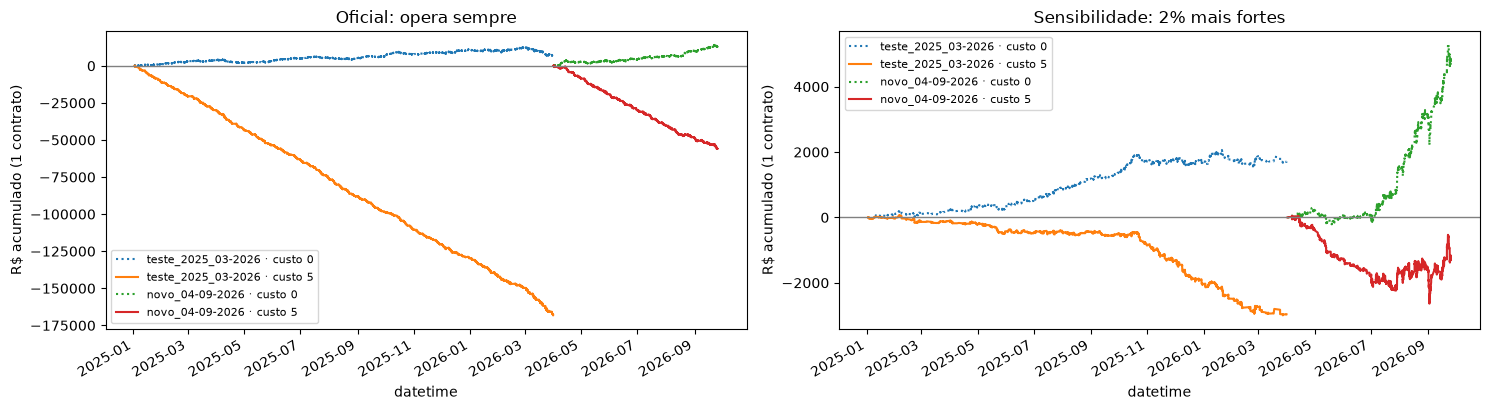

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, (regra, lim) in zip(axes, [("Oficial: opera sempre", 0.0), ("Sensibilidade: 2% mais fortes", LIM_SENS)]):
    for per in ["teste_2025_03-2026", "novo_04-09-2026"]:
        for custo, ls in [(0, ":"), (5, "-")]:
            ops = o.ops_por_candle(PREV[per], lim, custo)
            (ops.pontos.cumsum() * t.PONTO_WIN).plot(ax=ax, ls=ls, label=f"{per} · custo {custo}")
    ax.axhline(0, color="gray", lw=1); ax.set_title(regra); ax.set_ylabel("R$ acumulado (1 contrato)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/curva_capital_teste_B.png", dpi=150); plt.show()